In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = pd.read_csv('/content/NIFTY-02MAY24-01APR24.csv')

In [13]:

print("--- Dataset Info ---")
data.info()

print("\n--- Dataset Shape ---")
print(data.shape)

print("\n--- First 5 rows ---")
preview = data.head()
preview

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13274 entries, 0 to 13273
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       13274 non-null  object 
 1   strike_price   13274 non-null  int64  
 2   right          13274 non-null  object 
 3   open           13274 non-null  float64
 4   high           13274 non-null  float64
 5   low            13274 non-null  float64
 6   close          13274 non-null  float64
 7   open_interest  13274 non-null  int64  
 8   volume         13274 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 933.5+ KB

--- Dataset Shape ---
(13274, 9)

--- First 5 rows ---


,datetime,strike_price,right,open,high,low,close,open_interest,volume
0,09:31,21950,CE,634.85,634.85,634.85,634.85,0,0
1,09:15,22000,CE,682.20,682.20,682.20,682.20,0,0
2,09:16,22000,CE,682.20,682.20,682.20,682.20,0,0
3,09:17,22000,CE,682.20,682.20,682.20,682.20,0,0
4,09:18,22000,CE,682.20,682.20,682.20,682.20,0,0


In [14]:

print("--- Descriptive Statistics ---")
display(data.describe())

print("\n--- Minimum Values ---")
print(data.min(numeric_only=True))

print("\n--- Maximum Values ---")
print(data.max(numeric_only=True))

print("\n--- Unique Options Types (Right) ---")
print(data['right'].unique())

print("\n--- Value Counts for Option Types ---")
print(data['right'].value_counts())

--- Descriptive Statistics ---


,strike_price,open,high,low,close,open_interest,volume
count,13274.000000,13274.000000,13274.000000,13274.000000,13274.000000,13274.000000,13274.000000
mean,22371.289739,262.030394,262.106287,261.905533,261.982010,1924.634624,5.894983
std,577.143737,193.138898,193.159657,193.162337,193.183402,3826.250197,48.635582
min,21000.000000,12.050000,12.050000,12.050000,12.050000,0.000000,0.000000
25%,22050.000000,91.000000,91.000000,91.000000,91.000000,0.000000,0.000000
50%,22400.000000,221.450000,221.450000,221.175000,221.450000,100.000000,0.000000
75%,22650.000000,400.000000,400.000000,400.000000,400.000000,1950.000000,0.000000
max,24100.000000,820.000000,820.000000,820.000000,820.000000,18150.000000,1600.000000



--- Minimum Values ---
strike_price     21000.00
open                12.05
high                12.05
low                 12.05
close               12.05
open_interest        0.00
volume               0.00
dtype: float64

--- Maximum Values ---
strike_price     24100.0
open               820.0
high               820.0
low                820.0
close              820.0
open_interest    18150.0
volume            1600.0
dtype: float64

--- Unique Options Types (Right) ---
['CE' 'PE']

--- Value Counts for Option Types ---
right
CE    7287
PE    5987
Name: count, dtype: int64


In [15]:

print("--- Missing Values in Dataset ---")
print(data.isnull().sum())

# Checking and removing duplicate rows
duplicates_count = data.duplicated().sum()
print(f"\nTotal duplicate rows: {duplicates_count}")
if duplicates_count > 0:
    data = data.drop_duplicates()
    print("Duplicate rows successfully removed!")
    print(f"New dataset shape: {data.shape}")

--- Missing Values in Dataset ---
datetime         0
strike_price     0
right            0
open             0
high             0
low              0
close            0
open_interest    0
volume           0
dtype: int64

Total duplicate rows: 0


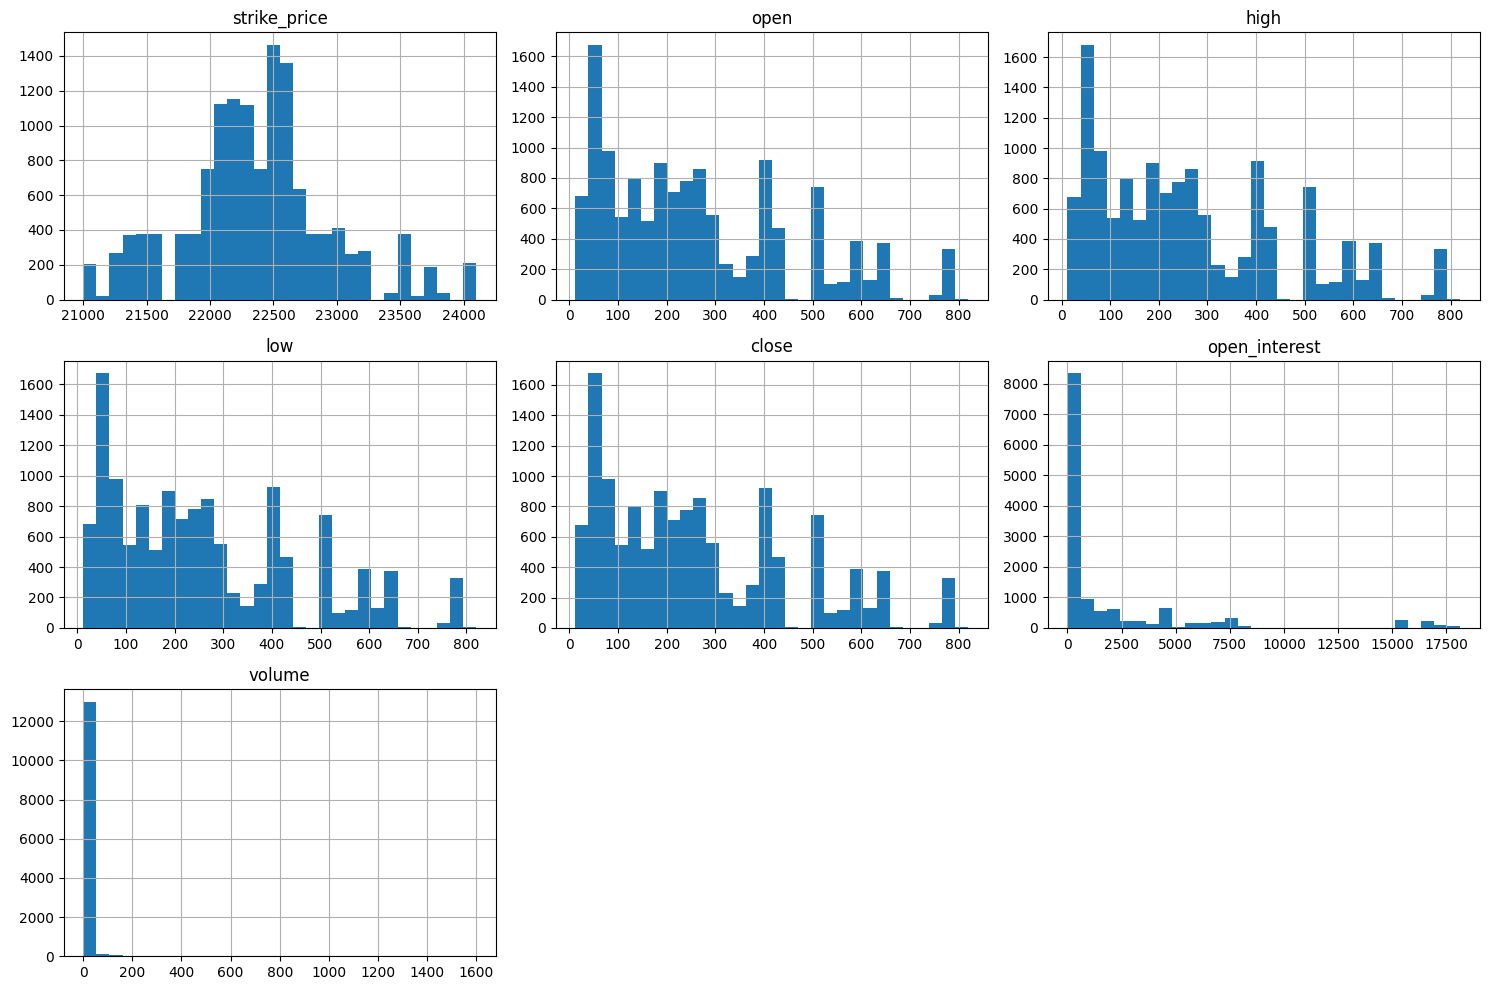

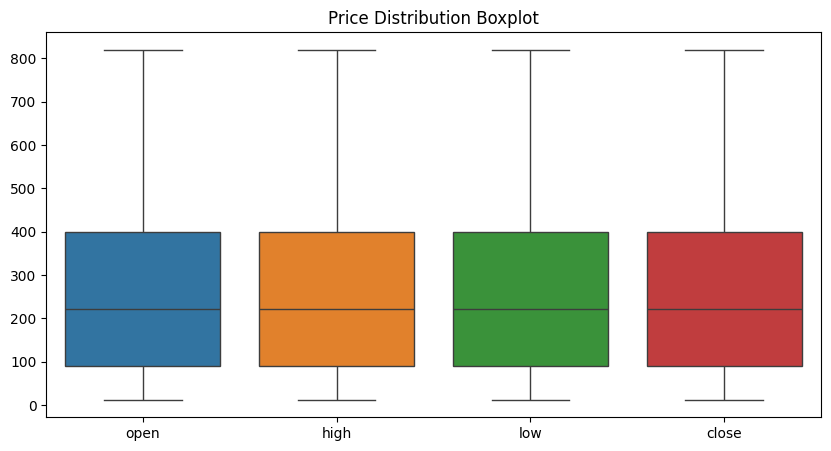

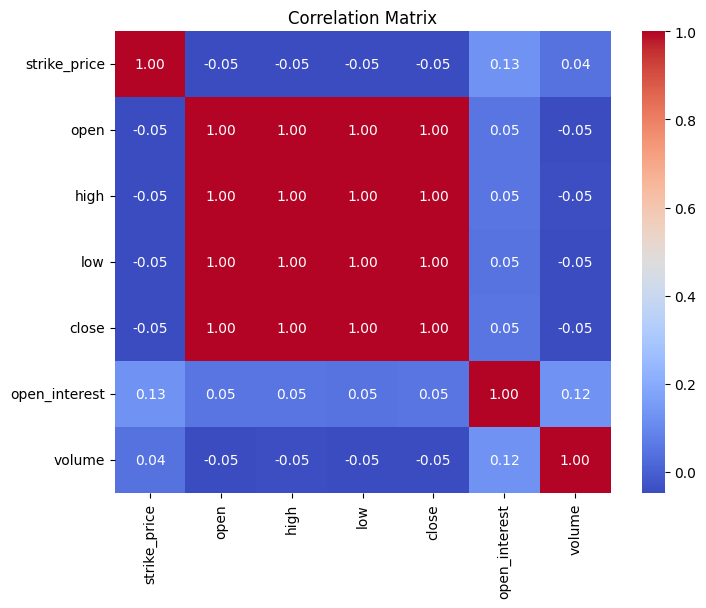

--- Average metrics grouped by Option Type (Right) ---


,strike_price,open,high,low,close,open_interest,volume
right,,,,,,,
CE,22671.915740,344.121346,344.215596,344.041258,344.137663,2384.986963,5.290243
PE,22005.386671,162.114448,162.167997,161.935093,161.987314,1364.322699,6.631034


In [16]:

data.hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=data[['open', 'high', 'low', 'close']])
plt.title('Price Distribution Boxplot')
plt.show()


plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()


print("--- Average metrics grouped by Option Type (Right) ---")
display(data.groupby('right').mean(numeric_only=True))